# Lab 1 : Image Generation Models: Autoencoders, GANs and VAEs 

In this lab, you will build and train three foundational generative models: Autoencoder, GAN, and VAE.



<table align="left">
  <td>
    <a href="https://colab.research.google.com/drive/1G9jZC0mQNoIXniUS27AJAc-Kscf8hm94?usp=sharing" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
  </td>
</table>

## Setup

In [10]:
!pip install torch torchvision matplotlib scikit-learn


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [11]:

import torch
from torch import nn, optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# check if it can be running on Mac M chip
if torch.backends.mps.is_available():
    device = torch.device("mps")
print("Using device:", device)


Using device: mps


## Load Dataset

In [12]:

transform = transforms.Compose([transforms.ToTensor()])
train_data = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
train_loader = DataLoader(train_data, batch_size=128, shuffle=True)


## Part 1 – Autoencoder

### Q1.1 - Encoder architecture
**Objective**: Implement the encoder part of an autoencoder using PyTorch.

You are working with grayscale images of size 28×28 pixels (e.g., MNIST). Your goal is to design an encoder that transforms each input image into a 64-dimensional latent representation.

Your encoder should meet the following requirements:
- Flatten the 28×28 input image into a 1D vector.
- Use a fully connected (linear) layer that maps the 784 input features to 128 units.
- Apply a ReLU activation after this first layer.
- Add a second fully connected (linear) layer that maps from 128 to the final latent dimension of 64.

Implement this encoder as a PyTorch module named Encoder.

In [13]:
class Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
        )
    def forward(self, x):
        return self.net(x)


### Q 1.2 - Decoder architecture
**Objective**: Implement the decoder part of an autoencoder using PyTorch.

In this task, you will design the decoder that reconstructs 28×28 grayscale images from a 64-dimensional latent vector (produced by an encoder).

Your decoder should follow these specifications:
- Start with a fully connected layer that maps the 64-dimensional latent space to 128 units.
- Apply a ReLU activation.
- Add another fully connected layer that maps from 128 to 784 (to reconstruct the flattened image).
- Use a Sigmoid activation to ensure output values are in the range [0, 1] (assuming images are normalized).
- Unflatten the output back into image format: shape = (1, 28, 28) (channel-first format for PyTorch).



In [14]:
class Decoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, 28 * 28),
            nn.Sigmoid(),
            nn.Unflatten(1, (1, 28, 28))
        )
    def forward(self, z):
        return self.net(z)


### Full Autoencoder architecture

In [15]:
class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = Encoder()
        self.decoder = Decoder()
    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)

model = Autoencoder().to(device)


### Q 1.3 - Training Setup
**Objective**: Set up the loss function and optimizer to train your autoencoder

Functions to use:
- nn.MSELoss() – to define the loss function
- optim.Adam(parameters, lr=1e-3) – to define the optimizer


In [16]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

In [17]:
# check the model structure
model.train()

Autoencoder(
  (encoder): Encoder(
    (net): Sequential(
      (0): Flatten(start_dim=1, end_dim=-1)
      (1): Linear(in_features=784, out_features=128, bias=True)
      (2): ReLU()
      (3): Linear(in_features=128, out_features=64, bias=True)
    )
  )
  (decoder): Decoder(
    (net): Sequential(
      (0): Linear(in_features=64, out_features=128, bias=True)
      (1): ReLU()
      (2): Linear(in_features=128, out_features=784, bias=True)
      (3): Sigmoid()
      (4): Unflatten(dim=1, unflattened_size=(1, 28, 28))
    )
  )
)

### Define the training loop

In [18]:
# Define the training loop
def train_model(model, train_loader, criterion, optimizer, epochs=20):
    model.train()
    losses = []
    for epoch in range(epochs):
        epoch_loss = 0
        for images, _ in train_loader:
            images = images.to(device)
            outputs = model(images)
            loss = criterion(outputs, images)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
        losses.append(epoch_loss / len(train_loader))
        print(f"Epoch {epoch+1}/{epochs}, Loss: {losses[-1]:.4f}")
    return losses
losses = train_model(model, train_loader, criterion, optimizer, epochs=20)


Epoch 1/20, Loss: 0.0358
Epoch 2/20, Loss: 0.0190
Epoch 3/20, Loss: 0.0163
Epoch 4/20, Loss: 0.0148
Epoch 5/20, Loss: 0.0136
Epoch 6/20, Loss: 0.0128
Epoch 7/20, Loss: 0.0121
Epoch 8/20, Loss: 0.0115
Epoch 9/20, Loss: 0.0111
Epoch 10/20, Loss: 0.0107
Epoch 11/20, Loss: 0.0104
Epoch 12/20, Loss: 0.0101
Epoch 13/20, Loss: 0.0099
Epoch 14/20, Loss: 0.0096
Epoch 15/20, Loss: 0.0094
Epoch 16/20, Loss: 0.0093
Epoch 17/20, Loss: 0.0091
Epoch 18/20, Loss: 0.0089
Epoch 19/20, Loss: 0.0088
Epoch 20/20, Loss: 0.0087


### Plot the losses vs epochs

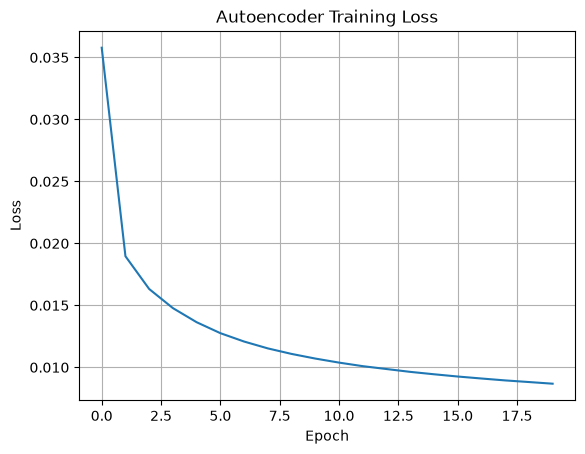

In [19]:
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Autoencoder Training Loss")
plt.grid(True)
plt.show()


### plot some examples

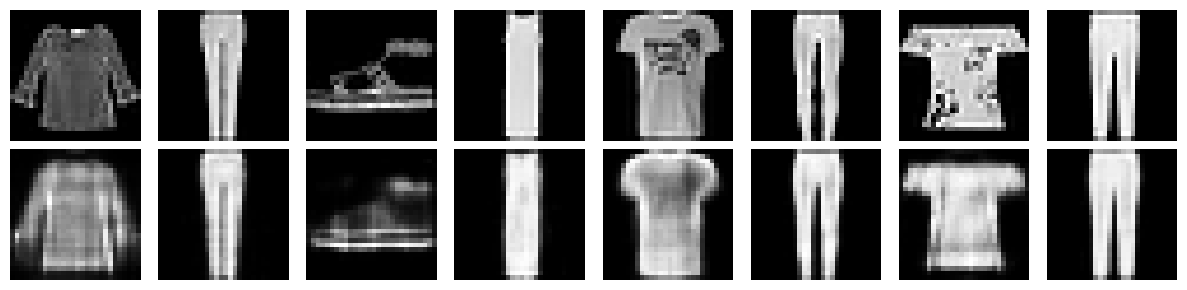

In [20]:
model.eval()
examples = next(iter(train_loader))[0][:8].to(device)
reconstructions = model(examples).detach().cpu()
fig, axs = plt.subplots(2, 8, figsize=(12, 3))
for i in range(8):
    axs[0, i].imshow(examples[i].cpu().squeeze(), cmap='gray')
    axs[0, i].axis('off')
    axs[1, i].imshow(reconstructions[i].squeeze(), cmap='gray')
    axs[1, i].axis('off')
axs[0, 0].set_ylabel("Original")
axs[1, 0].set_ylabel("Reconstructed")
plt.tight_layout()
plt.show()


### Visualisation of the latent space

To better understand how your autoencoder is encoding the data, it’s helpful to visualize the latent representations.

The function below uses t-SNE, a dimensionality reduction technique, to project the high-dimensional latent vectors into 2D space. It then:
- Plots each point in 2D, colored by its class (e.g., digit label).
- Overlays example images on the scatter plot to see what kinds of digits are represented in each part of the latent space.
- This helps us visually assess clustering, separation between classes, and the structure of the learned latent space.

You can call this visualization after training, using a small sample of the validation set and the corresponding labels.

In [21]:
def visualise_latent_space(X_valid, X_valid_compressed, y_valid):
    from sklearn.manifold import TSNE
    tsne = TSNE()
    X_valid_2D = tsne.fit_transform(X_valid_compressed)
    X_valid_2D = (X_valid_2D - X_valid_2D.min()) / (X_valid_2D.max() - X_valid_2D.min())
    plt.figure(figsize=(10, 8))
    cmap = plt.cm.tab10
    plt.scatter(X_valid_2D[:, 0], X_valid_2D[:, 1], c=y_valid, s=10, cmap=cmap)
    image_positions = np.array([[1., 1.]])
    for index, position in enumerate(X_valid_2D):
        dist = np.sum((position - image_positions) ** 2, axis=1)
        if np.min(dist) > 0.02: # if far enough from other images
            image_positions = np.r_[image_positions, [position]]
            img = X_valid[index].cpu().numpy().squeeze()  # shape (28, 28)
            imagebox = mpl.offsetbox.AnnotationBbox(
                mpl.offsetbox.OffsetImage(img, cmap="binary"),
                position, bboxprops={"edgecolor": cmap(y_valid[index]), "lw": 2})
            plt.gca().add_artist(imagebox)
    plt.axis("off")
    plt.show()

def visualise_AE_latent_space(model, train_data):
    X_valid = train_data.data[:1000].float() / 255.0
    X_valid = X_valid.unsqueeze(1).to(device)
    X_valid_compressed = model.encoder(X_valid).detach().cpu()
    y_valid = train_data.targets[:1000]
    visualise_latent_space(X_valid, X_valid_compressed, y_valid)

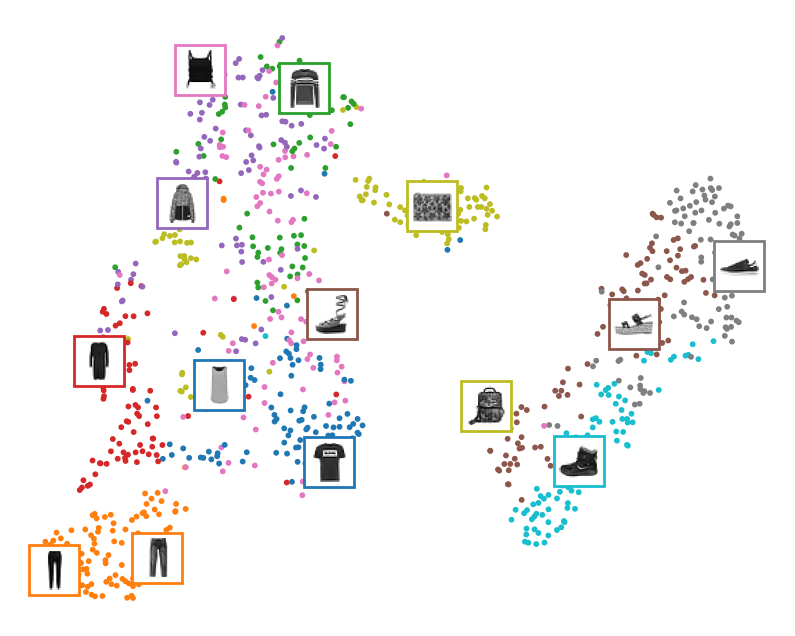

In [22]:
visualise_AE_latent_space(model, train_data)

# Part 2 - Variational Autoencoder (VAE)

A Variational Autoencoder (VAE) is a generative model that learns not just to reconstruct inputs like a standard autoencoder, but also to generate new data by sampling from a latent space.

Unlike regular autoencoders that map each input to a fixed point in the latent space, a VAE:
- Maps each input to a distribution (typically Gaussian),
- Samples from this distribution during training,
- Adds a regularization term (the KL divergence) to force the latent space to follow a standard normal distribution.

This approach allows the VAE to generate more diverse, realistic samples by decoding random points from a continuous, well-structured latent space.


### 2.1 The Encoder Architecture:
The VAEEncoder is the encoder module of the VAE. It processes the input image and outputs two vectors:
- The mean (mu) of the latent distribution
- The log-variance (logvar) of the latent distribution

These two parameters define the Gaussian distribution from which we sample the latent vector.

Here’s how the encoder is structured:

**Convolutional Layers (self.conv)**
- Input: grayscale image of shape [B, 1, 28, 28]
- A sequence of 3 convolutional layers reduces spatial dimensions:
- Conv1: 1 → 32 channels, size becomes [B, 32, 14, 14]
- Conv2: 32 → 64 channels, size becomes [B, 64, 7, 7]
- Conv3: 64 → 128 channels, size stays [B, 128, 7, 7]
- The output is flattened into a vector of size [B, 128×7×7]

**Fully Connected Layers (self.fc)**
- A Linear layer reduces the size to 256 features and applies ReLU.

**Latent Heads (self.mu and self.logvar)**
- Two separate linear layers generate:
- mu: the mean vector of the latent distribution.
- logvar: the log-variance vector.

**KL Divergence Term**
- The encoder also computes the KL divergence between the predicted Gaussian and the standard normal distribution.
- This term is used later in the VAE’s loss function to regularize the latent space.

In [23]:
class VAEEncoder(nn.Module):
    def __init__(self, latent_dim=50):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=2, padding=1),  # [B, 32, 14, 14]
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1), # [B, 64, 7, 7]
            nn.ReLU(),
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1), # [B, 128, 7, 7]
            nn.ReLU(),
            nn.Flatten()
        )
        self.fc = nn.Sequential(
            nn.Linear(128 * 7 * 7, 256),
            nn.ReLU()
        )
        self.mu = nn.Linear(256, latent_dim)
        self.logvar = nn.Linear(256, latent_dim)
    def forward(self, x):
        h = self.conv(x)
        h = self.fc(h)
        return self.mu(h), self.logvar(h)

### Q2.2 VAE – Decoder Implementation

**Objective**: Implement the decoder part of a Variational Autoencoder (VAE) using PyTorch.
You have already built the VAE encoder, which transforms an image into a latent distribution (mean and log-variance). Now, you will implement the decoder, which takes a sample from the latent space and reconstructs the original image.

Your task is to build a PyTorch nn.Module named VAEDecoder that:
-  Input: Takes a latent vector of size latent_dim (e.g., 50).
- Passes it through two fully connected layers:
	- First layer: latent_dim → 256, 
	- ReLU activation.
	- Second layer: 256 → 128 × 7 × 7.
	- ReLU activation.
- Unflattens the output to shape [128, 7, 7] to prepare for convolutional decoding.
- Passes the result through three transposed convolution layers to upscale the image:
	- ConvTranspose2d: (128, 64, kernel_size=3, stride=1, padding=1), preserves shape [7×7]
	- ReLU activation
	- ConvTranspose2d: (64, 32, kernel_size=3, stride=2, padding=1, output_padding=1), upsamples to [14×14]
	- ReLU activation
	- ConvTranspose2d: (32, 1, kernel_size=3, stride=2, padding=1, output_padding=1), upsamples to [28×28]
- Applies a final Sigmoid activation to ensure output pixel values are between 0 and 1.

Use nn.Sequential() blocks to structure your model, and define the forward() method to return the reconstructed image.


In [31]:
# create the decoder with conv layers
class VAEDecoder(nn.Module):
    def __init__(self, latent_dim=50):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 128 * 7 * 7),
            nn.ReLU(),
        )
        self.deconv = nn.Sequential(
            nn.Unflatten(1, (128, 7, 7)),
            nn.ConvTranspose2d(128, 64, kernel_size=3, stride=1, padding=1), # [B, 64, 7, 7]
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1), # [B, 32, 14, 14]
            nn.ReLU(),
            nn.ConvTranspose2d(32, 1, kernel_size=3, stride=2, padding=1, output_padding=1), # [B, 1, 28, 28]
            nn.Sigmoid(),
        )
    def forward(self, z):
        h = self.fc(z)
        x_recon = self.deconv(h)
        return x_recon

### 2.3 The VAE full architecture

In [32]:
class VAE(nn.Module):
    def __init__(self, latent_dim=50):
        super().__init__()
        self.encoder = VAEEncoder(latent_dim)
        self.decoder = VAEDecoder(latent_dim)
    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std
    def forward(self, x):
        mu, logvar = self.encoder(x)
        z = self.reparameterize(mu, logvar)
        recon = self.decoder(z)
        return recon, mu, logvar    

**VAE Loss** : it combines two components:
- Reconstruction Loss (how well the image is reconstructed)
- KL Divergence (how close the latent distribution is to a standard normal distribution)

In [33]:
def vae_loss(recon_x, x, mu, logvar):
    BCE = nn.functional.binary_cross_entropy(recon_x, x, reduction='sum')
    KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return BCE + KLD


**Model instance**: create a model instance with a latent space of dimension 30

In [34]:
VAE_model = VAE(latent_dim=30).to(device)

In [35]:
# Training loop for VAE
def train_vae(model, train_loader,optimizer, epochs=20):
    vae_losses = []
    model.train()
    for epoch in range(epochs):
        epoch_loss = 0
        for images, _ in train_loader:
            images = images.to(device)
            recon, mu, logvar = model(images)
            loss = vae_loss(recon, images, mu, logvar)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
        vae_losses.append(epoch_loss / len(train_loader))
        print(f"Epoch {epoch+1}/{epochs}, Loss: {vae_losses[-1]:.4f}")
    return vae_losses

### Q2.4 : define the optimizer and run the training loop
Functions to use:
- optim.Adam(model.parameters, lr=1e-3) – to define the optimizer
- losses = train_vae(...)

In [36]:
# To complete: define the optimizer and run the training loop
optimizer = optim.Adam(VAE_model.parameters(), lr=1e-3)
losses = train_vae(VAE_model, train_loader, optimizer, epochs=20)

Epoch 1/20, Loss: 36453.4706
Epoch 2/20, Loss: 31922.2559
Epoch 3/20, Loss: 31343.7947
Epoch 4/20, Loss: 31022.9423
Epoch 5/20, Loss: 30836.2747
Epoch 6/20, Loss: 30689.2137
Epoch 7/20, Loss: 30580.2361
Epoch 8/20, Loss: 30511.5254
Epoch 9/20, Loss: 30437.8287
Epoch 10/20, Loss: 30389.0391
Epoch 11/20, Loss: 30329.5081
Epoch 12/20, Loss: 30291.1972
Epoch 13/20, Loss: 30242.8101
Epoch 14/20, Loss: 30207.7169
Epoch 15/20, Loss: 30178.1783
Epoch 16/20, Loss: 30165.7286
Epoch 17/20, Loss: 30127.7443
Epoch 18/20, Loss: 30108.5226
Epoch 19/20, Loss: 30094.1728
Epoch 20/20, Loss: 30074.7878


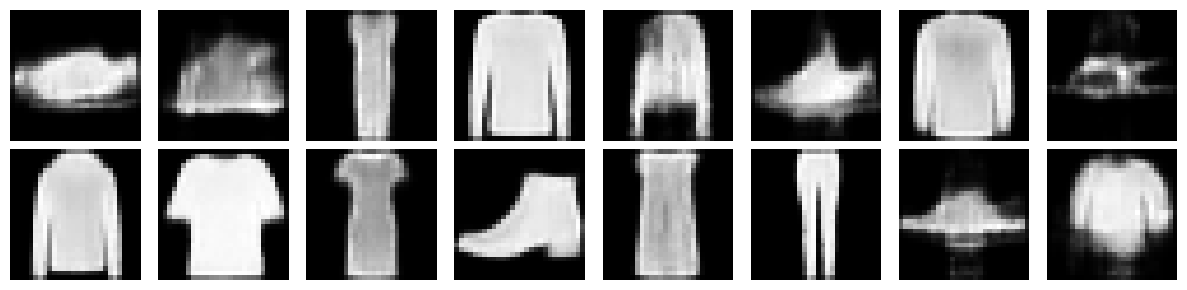

In [37]:
# Generate some images from the trained VAE
VAE_model.eval()
noise = torch.randn(16, 30).to(device)  # latent_dim=30
generated_images = VAE_model.decoder(noise).detach().cpu()
fig, axs = plt.subplots(2, 8, figsize=(12, 3))
for i in range(2):
    for j in range(8):
        axs[i, j].imshow(generated_images[i*8 + j].squeeze(), cmap='gray')
        axs[i, j].axis('off')
plt.tight_layout()
plt.show()

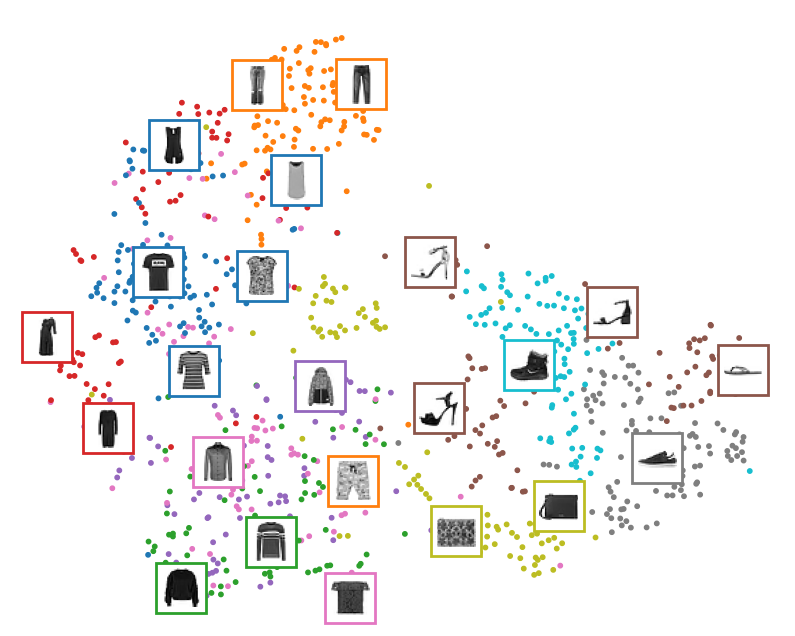

In [38]:
# visualise the latent space of VAE
def visualise_VAE_latent_space(model, train_data):
    X_valid = train_data.data[:1000].float() / 255.0
    X_valid = X_valid.unsqueeze(1).to(device)
    X_valid_compressed = model.encoder(X_valid)[0].detach().cpu()
    y_valid = train_data.targets[:1000]
    visualise_latent_space(X_valid, X_valid_compressed, y_valid)


visualise_VAE_latent_space(VAE_model, train_data)

#### Now Try with a wider latent space, e.g. dim = 50, and increase the number of epochs to 50

In [39]:
vae_50 = VAE(latent_dim=50).to(device)
optimizer = optim.Adam(vae_50.parameters(), lr=1e-3)
losses = train_vae(vae_50, train_loader, optimizer, epochs=50)

Epoch 1/50, Loss: 36711.2456
Epoch 2/50, Loss: 32306.7180
Epoch 3/50, Loss: 31443.9669
Epoch 9/50, Loss: 30446.4101
Epoch 10/50, Loss: 30392.5426
Epoch 11/50, Loss: 30344.1337
Epoch 12/50, Loss: 30305.5213
Epoch 13/50, Loss: 30262.8554
Epoch 14/50, Loss: 30223.9926
Epoch 15/50, Loss: 30188.4540
Epoch 16/50, Loss: 30164.7474
Epoch 17/50, Loss: 30141.3517
Epoch 18/50, Loss: 30124.4294
Epoch 19/50, Loss: 30097.6165
Epoch 20/50, Loss: 30080.6584
Epoch 21/50, Loss: 30066.5096
Epoch 22/50, Loss: 30050.1828
Epoch 23/50, Loss: 30037.5923
Epoch 24/50, Loss: 30024.9372
Epoch 25/50, Loss: 30010.8548
Epoch 26/50, Loss: 29999.4557
Epoch 27/50, Loss: 29981.4193
Epoch 28/50, Loss: 29970.1313
Epoch 29/50, Loss: 29960.8380
Epoch 30/50, Loss: 29950.6294
Epoch 31/50, Loss: 29945.2607
Epoch 32/50, Loss: 29929.7898
Epoch 33/50, Loss: 29929.2714
Epoch 34/50, Loss: 29910.6974
Epoch 35/50, Loss: 29903.3078
Epoch 36/50, Loss: 29892.9404
Epoch 37/50, Loss: 29889.8138
Epoch 38/50, Loss: 29879.9031
Epoch 39/50, L

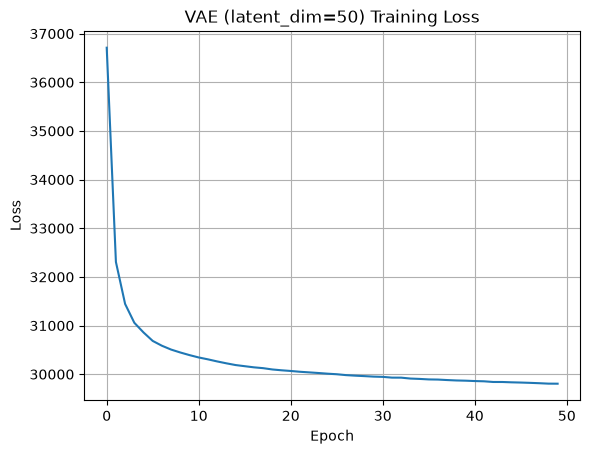

In [40]:
# plot the training loss over the epochs
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VAE (latent_dim=50) Training Loss")
plt.grid(True)
plt.show()

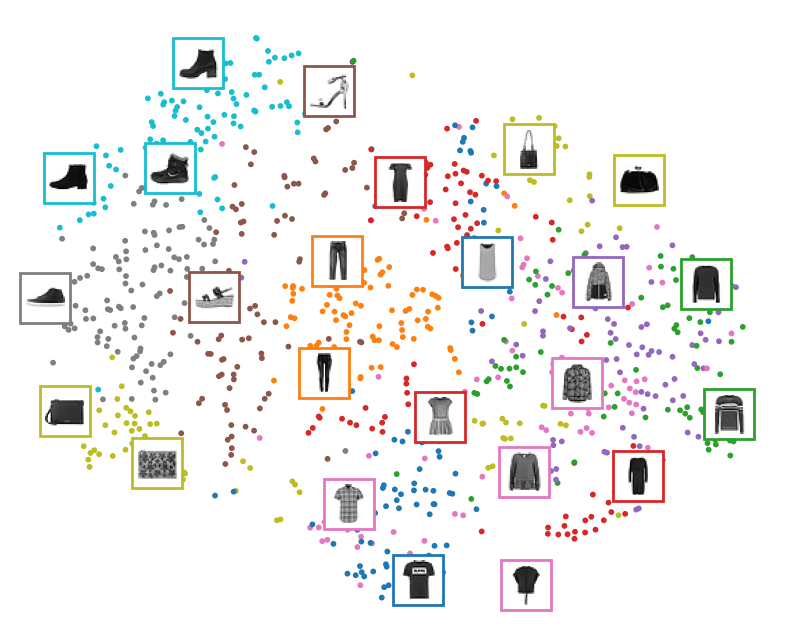

In [41]:
# visualise the latent space
visualise_VAE_latent_space(vae_50, train_data)

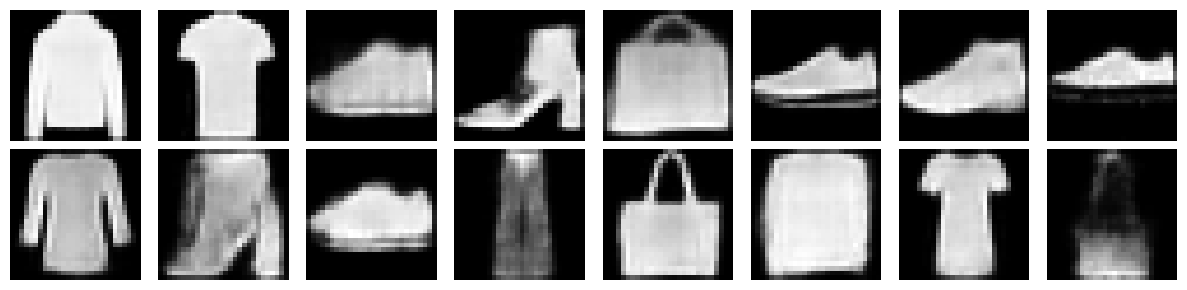

In [42]:
# plot some images from the vae
vae_50.eval()
noise = torch.randn(16, 50).to(device)
generated_images = vae_50.decoder(noise).detach().cpu()
fig, axs = plt.subplots(2, 8, figsize=(12, 3))
for i in range(2):
    for j in range(8):
        axs[i, j].imshow(generated_images[i*8 + j].squeeze(), cmap='gray')
        axs[i, j].axis('off')
plt.tight_layout()
plt.show()

## Part 3 – Generative Adversarial Network (GAN)

### 3.1 Generator Architecture:
- Takes in random noise (a latent vector) and tries to generate fake images that look like real ones (e.g., MNIST digits).
- Learns to fool the discriminator over time.
- Components:
    - Fully connected layer to expand the latent vector.
    - Output reshaped into a 28×28 image

In [43]:
class Generator(nn.Module):
    def __init__(self, latent_dim=100):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 28*28),
            nn.Tanh()
        )
    def forward(self, z):
        return self.model(z).view(-1, 1, 28, 28)


### 3.2 Discriminator architecture:
- Receives both real images (from the dataset) and fake images (from the generator).
- Tries to distinguish real from fake — outputs a probability: “real” (1) or “fake” (0).
- Components:
    - Input: A 28×28 image (real or generated)
    - Flattened input passed through fully connected layers
    - Uses LeakyReLU to allow a small gradient when inactive
    - Final activation: Sigmoid, outputting a probability (real/fake)

In [44]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28, 128),
            nn.LeakyReLU(0.2),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )
    def forward(self, x):
        return self.model(x)


**Instance setup**

In [45]:
latent_dim = 100
generator = Generator(latent_dim).to(device)
discriminator = Discriminator().to(device)
criterion = nn.BCELoss()
opt_g = optim.Adam(generator.parameters(), lr=2e-4)
opt_d = optim.Adam(discriminator.parameters(), lr=2e-4)


**Check the generator output**

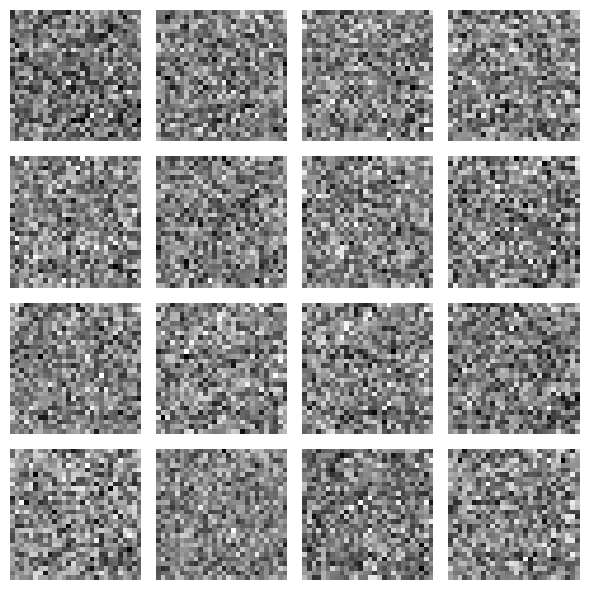

In [46]:
# Generate some samples from the generator
z = torch.randn(16, latent_dim).to(device)
generated_images = generator(z).detach().cpu()
fig, axs = plt.subplots(4, 4, figsize=(6, 6))
for i in range(4):
    for j in range(4):
        axs[i, j].imshow(generated_images[i*4 + j].squeeze(), cmap='gray')
        axs[i, j].axis('off')
plt.tight_layout()
plt.show()

Discriminator loss on real and fake images: 0.6980


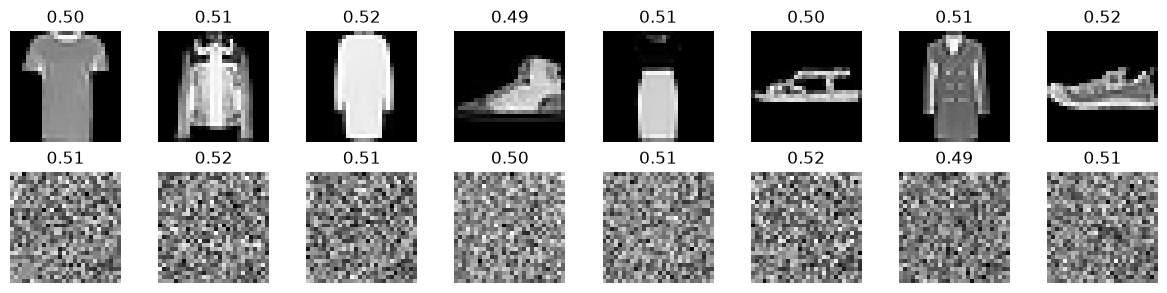

In [47]:
# Test the discriminator
real_images = next(iter(train_loader))[0][:16].to(device)
real_labels = torch.ones(16, 1).to(device)
fake_images = generator(torch.randn(16, latent_dim).to(device)).detach()
fake_labels = torch.zeros(16, 1).to(device)
real_preds = discriminator(real_images)
fake_preds = discriminator(fake_images)
real_loss = criterion(real_preds, real_labels)
fake_loss = criterion(fake_preds, fake_labels)
d_loss = (real_loss + fake_loss) / 2
print(f"Discriminator loss on real and fake images: {d_loss.item():.4f}")
# show some images from both sets and what are the discriminator outputs
fig, axs = plt.subplots(2, 8, figsize=(12, 3))
for i in range(8):
    axs[0, i].imshow(real_images[i].cpu().squeeze(), cmap='gray')
    axs[0, i].set_title(f"{real_preds[i].item():.2f}")
    axs[0, i].axis('off')
    axs[1, i].imshow(fake_images[i].cpu().squeeze(), cmap='gray')
    axs[1, i].set_title(f"{fake_preds[i].item():.2f}")
    axs[1, i].axis('off')
axs[0, 0].set_ylabel("Real")
axs[1, 0].set_ylabel("Fake")
plt.tight_layout()
plt.show()

In [48]:
def generate_noise(batch_size, latent_dim):
    return torch.randn(batch_size, latent_dim).to(device)


#### Train the GANs

In [49]:
# Training loop for GANs

def train_GANS(generator, discriminator, train_loader, latent_dim=100, epochs=50):
    g_losses = []
    d_losses = []
    for epoch in range(epochs):
        # Initialize epoch losses
        g_loss_epoch, d_loss_epoch = 0, 0

        # Iterate over the training data
        for real, _ in train_loader:
            real = real.to(device)  
            batch_size = real.size(0)  

            # === Train Discriminator ===

            # Step 1: Generate fake images
            noise = generate_noise(batch_size, latent_dim)  # Sample random noise vector
            fake = generator(noise)  # Generate fake images from the noise using generator

            # Step 2: Compute discriminator outputs for real and fake images
            d_real = discriminator(real).view(-1)  # Discriminator output on real images
            d_fake = discriminator(fake.detach()).view(-1)  # Discriminator output on fake (detach to avoid updating G)

            # Step 3: Compute discriminator loss
            # - Real images should be classified as 1 (real)
            # - Fake images should be classified as 0 (fake)
            loss_d = criterion(d_real, torch.ones_like(d_real)) + \
                    criterion(d_fake, torch.zeros_like(d_fake))

            # Step 4: Backpropagation and optimization step for discriminator
            opt_d.zero_grad()  # Zero out discriminator gradients
            loss_d.backward()  # Backpropagate discriminator loss
            opt_d.step()       # Update discriminator weights

            # === Train Generator ===

            # Step 5: Generate new fake images (detach not used here since we want gradients to flow)
            noise = generate_noise(batch_size, latent_dim)
            fake = generator(noise)

            # Step 6: Compute discriminator output on the newly generated fake images
            d_output = discriminator(fake).view(-1)

            # Step 7: Compute generator loss
            # - The generator wants the discriminator to think its outputs are real (target = 1)
            loss_g = criterion(d_output, torch.ones_like(d_output))

            # Step 8: Backpropagation and optimization step for generator
            opt_g.zero_grad()  # Zero out generator gradients
            loss_g.backward()  # Backpropagate generator loss
            opt_g.step()       # Update generator weights

            # Accumulate losses for this batch
            d_loss_epoch += loss_d.item()
            g_loss_epoch += loss_g.item()

        # Record average losses for the epoch
        d_losses.append(d_loss_epoch / len(train_loader))
        g_losses.append(g_loss_epoch / len(train_loader))

        # Print losses to track training progress
        print(f"Epoch {epoch+1}: D Loss = {d_losses[-1]:.4f}, G Loss = {g_losses[-1]:.4f}")
    return g_losses, d_losses

In [50]:
g_losses, d_losses = train_GANS(generator, discriminator, train_loader, latent_dim=latent_dim, epochs=25)

Epoch 1: D Loss = 0.8789, G Loss = 1.0867
Epoch 2: D Loss = 1.1207, G Loss = 0.9038
Epoch 3: D Loss = 0.9585, G Loss = 1.0150
Epoch 4: D Loss = 0.9847, G Loss = 0.9641
Epoch 5: D Loss = 1.0114, G Loss = 1.1411
Epoch 6: D Loss = 0.9683, G Loss = 1.1561
Epoch 7: D Loss = 1.0999, G Loss = 1.0303
Epoch 8: D Loss = 1.0883, G Loss = 1.0150
Epoch 9: D Loss = 1.1265, G Loss = 0.9861
Epoch 10: D Loss = 1.0639, G Loss = 1.0159
Epoch 11: D Loss = 1.1234, G Loss = 0.9318
Epoch 12: D Loss = 1.0611, G Loss = 1.0525
Epoch 13: D Loss = 1.0557, G Loss = 1.0536
Epoch 14: D Loss = 1.1061, G Loss = 0.9805
Epoch 15: D Loss = 1.0932, G Loss = 1.0382
Epoch 16: D Loss = 1.1918, G Loss = 0.9590
Epoch 17: D Loss = 1.2259, G Loss = 0.9524
Epoch 18: D Loss = 1.1515, G Loss = 1.0153
Epoch 19: D Loss = 1.2239, G Loss = 0.9494
Epoch 20: D Loss = 1.2376, G Loss = 0.9546
Epoch 21: D Loss = 1.2628, G Loss = 0.8999
Epoch 22: D Loss = 1.2471, G Loss = 0.8930
Epoch 23: D Loss = 1.2195, G Loss = 0.9601
Epoch 24: D Loss = 1

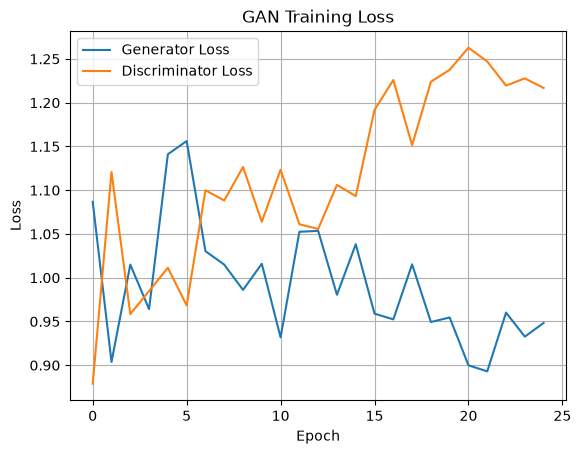

In [51]:
plt.plot(g_losses, label='Generator Loss')
plt.plot(d_losses, label='Discriminator Loss')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("GAN Training Loss")
plt.grid(True)
plt.show()


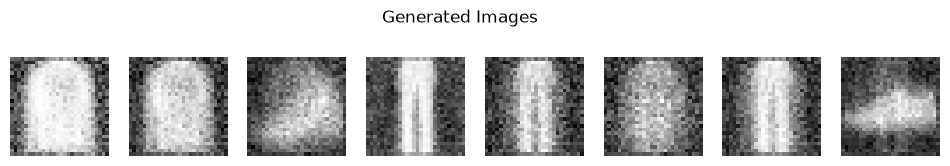

In [52]:
generator.eval()
noise = generate_noise(8, latent_dim)
samples = generator(noise).detach().cpu()
fig, axs = plt.subplots(1, 8, figsize=(12, 2))
for i in range(8):
    axs[i].imshow(samples[i].squeeze(), cmap="gray")
    axs[i].axis("off")
plt.suptitle("Generated Images")
plt.show()


### Q 3.1 : Repeate the training of gans with more epochs, and generate samples for comapison

In [53]:
generator.eval()
fixed_noise = generate_noise(16, latent_dim)
samples_25 = generator(fixed_noise).detach().cpu()

generator_long = Generator(latent_dim).to(device)
discriminator_long = Discriminator().to(device)
opt_g = optim.Adam(generator_long.parameters(), lr=2e-4)
opt_d = optim.Adam(discriminator_long.parameters(), lr=2e-4)
g_losses_long, d_losses_long = train_GANS(generator_long, discriminator_long, train_loader, latent_dim=latent_dim, epochs=100)
generator_long.eval()

Epoch 1: D Loss = 0.8942, G Loss = 1.0779
Epoch 2: D Loss = 1.0387, G Loss = 0.9859
Epoch 3: D Loss = 0.9041, G Loss = 1.0289
Epoch 4: D Loss = 0.9804, G Loss = 1.0079
Epoch 5: D Loss = 0.9883, G Loss = 1.1353
Epoch 6: D Loss = 1.0437, G Loss = 1.0554
Epoch 7: D Loss = 1.0243, G Loss = 1.0381
Epoch 8: D Loss = 1.0402, G Loss = 1.0159
Epoch 9: D Loss = 1.0244, G Loss = 1.0605
Epoch 10: D Loss = 0.9722, G Loss = 1.0870
Epoch 11: D Loss = 1.0864, G Loss = 1.0562
Epoch 12: D Loss = 0.9955, G Loss = 1.1221
Epoch 13: D Loss = 1.1104, G Loss = 1.0128
Epoch 14: D Loss = 0.9356, G Loss = 1.1739
Epoch 15: D Loss = 1.0785, G Loss = 1.0112
Epoch 16: D Loss = 1.0531, G Loss = 1.0486
Epoch 17: D Loss = 1.0386, G Loss = 1.1085
Epoch 18: D Loss = 1.1007, G Loss = 1.0821
Epoch 19: D Loss = 1.0124, G Loss = 1.1499
Epoch 20: D Loss = 1.1512, G Loss = 1.0002
Epoch 21: D Loss = 1.1072, G Loss = 1.0140
Epoch 22: D Loss = 1.0835, G Loss = 1.0564
Epoch 23: D Loss = 1.0709, G Loss = 1.0572
Epoch 24: D Loss = 1

Generator(
  (model): Sequential(
    (0): Linear(in_features=100, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=784, bias=True)
    (3): Tanh()
  )
)

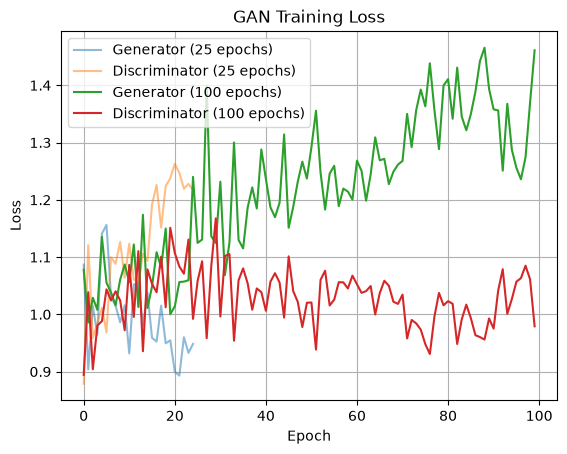

In [54]:
plt.plot(g_losses, label="Generator (25 epochs)", alpha=0.5)
plt.plot(d_losses, label="Discriminator (25 epochs)", alpha=0.5)
plt.plot(g_losses_long, label="Generator (100 epochs)")
plt.plot(d_losses_long, label="Discriminator (100 epochs)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("GAN Training Loss")
plt.grid(True)
plt.show()

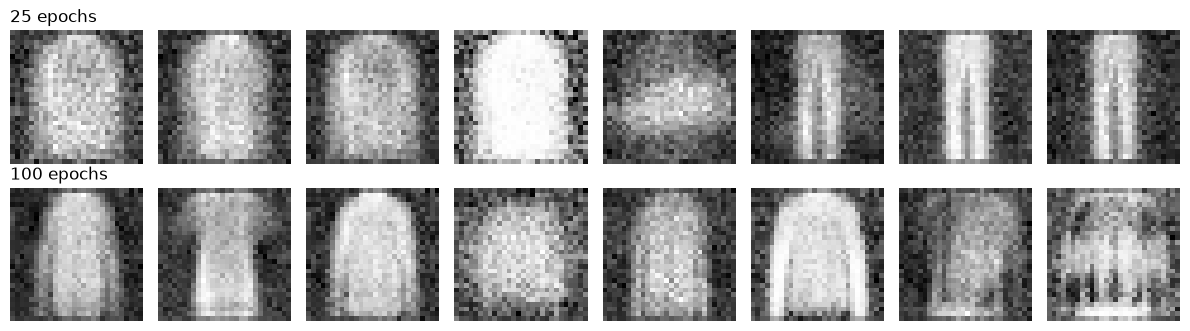

In [55]:
fig, axs = plt.subplots(2, 8, figsize=(12, 3.4))
for j in range(8):
    axs[0, j].imshow(samples_25[j].squeeze(), cmap="gray")
    axs[1, j].imshow(generator_long(fixed_noise[j:j + 1]).detach().cpu().squeeze(), cmap="gray")
    axs[0, j].axis("off")
    axs[1, j].axis("off")
axs[0, 0].set_title("25 epochs", loc="left")
axs[1, 0].set_title("100 epochs", loc="left")
plt.tight_layout()
plt.show()

### Report : Comments on your findings after trying the previous models for image generation

The autoencoder reconstructs the images well (final MSE of 0.0087), but they are a bit blurry and its latent space cannot be used to generate new images. The t-SNE shows clear groups for trousers and shoes, while shirts, pullovers and coats are mixed together. The VAE can generate new images from random noise: we get clothes, shoes and bags that we can recognise, but they are blurry. Going from 30 to 50 latent dimensions and from 20 to 50 epochs only lowers the loss a little (about 30,075 to 29,805), so we cannot say it really improves the results.

The GAN gives the worst results. Its images have the right shapes but a noisy grey background, and they are not very diverse. Training for 100 epochs instead of 25 does not clearly help: the generator loss goes up while the discriminator gets stronger. This is probably caused by the Tanh output combined with data in [0, 1] and by the small networks, but we did not test it. Overall, the autoencoder is the best at reconstruction, and the VAE is the most useful model to generate images in this lab.